In [7]:
from pathlib import Path
import warnings
import json
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for folder in [MODEL_DIR, REPORT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

print("Project directory:", PROJECT_DIR.resolve())

Project directory: D:\Projects\employee-attrition-prediction


In [10]:
df = pd.read_csv("D:/Projects/employee-attrition-prediction/data/WA_Fn-UseC_-HR-Employee-Attrition.csv")

# Create Tenure Bands
df["TenureBand"] = pd.cut(
    df["YearsAtCompany"],
    bins=[-1, 3, 10, np.inf],
    labels=["Short", "Medium", "Long"]
)

# Create a transparent workload/travel proxy.
# This is NOT a validated work-life balance measure.
overtime_score = df["OverTime"].map({"No": 0, "Yes": 1})

travel_score = df["BusinessTravel"].map({
    "Non-Travel": 0,
    "Travel_Rarely": 1,
    "Travel_Frequently": 2
})

df["WorkLifeRiskIndex"] = overtime_score + travel_score

# Promotion gap already exists as YearsSinceLastPromotion.
# Rename it instead of duplicating the same information.
df = df.rename(
    columns={"YearsSinceLastPromotion": "PromotionGap"}
)

display(df[[
    "YearsAtCompany",
    "TenureBand",
    "OverTime",
    "BusinessTravel",
    "WorkLifeRiskIndex",
    "PromotionGap"
]].head(10))

,YearsAtCompany,TenureBand,OverTime,BusinessTravel,WorkLifeRiskIndex,PromotionGap
0,6,Medium,Yes,Travel_Rarely,2,0
1,10,Medium,No,Travel_Frequently,2,1
2,0,Short,Yes,Travel_Rarely,2,0
3,8,Medium,Yes,Travel_Frequently,3,3
4,2,Short,No,Travel_Rarely,1,2
5,7,Medium,No,Travel_Frequently,2,3
6,1,Short,Yes,Travel_Rarely,2,0
7,1,Short,No,Travel_Rarely,1,0
8,9,Medium,No,Travel_Frequently,2,1
9,7,Medium,No,Travel_Rarely,1,7


In [13]:
# Constant columns and employee identifier
columns_to_drop = [
    "EmployeeCount",
    "EmployeeNumber",
    "Over18",
    "StandardHours"
]

df = df.drop(columns=columns_to_drop, errors="ignore")

X = df.drop(columns=["Attrition"])
y = df["Attrition"].map({"No": 0, "Yes": 1})

assert y.notna().all(), "Unexpected target labels found."

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature matrix: (1470, 32)
Target: (1470,)

Target distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64


In [16]:
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'PromotionGap', 'YearsWithCurrManager', 'WorkLifeRiskIndex']

Categorical features: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime', 'TenureBand']


C:\Users\adity\AppData\Local\Temp\ipykernel_15724\3959600475.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining attrition rate:")
print(round(y_train.mean() * 100, 2), "%")

print("Testing attrition rate:")
print(round(y_test.mean() * 100, 2), "%")

Training records: 1176
Testing records: 294

Training attrition rate:
16.16 %
Testing attrition rate:
15.99 %


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_preprocessor, numerical_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        class_weight="balanced",
        verbosity=-1,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "CatBoost": CatBoostClassifier(
        iterations=300,
        depth=5,
        learning_rate=0.05,
        verbose=0,
        random_seed=RANDOM_STATE,
        allow_writing_files=False,
        auto_class_weights="Balanced"
    )
}

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.pipeline import Pipeline

trained_models = {}
results = []

for model_name, model in models.items():
    print(f"Training: {model_name}")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    start_time = time.time()
    pipeline.fit(X_train, y_train)
    training_time = time.time() - start_time

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[model_name] = pipeline

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "PR_AUC": average_precision_score(y_test, y_prob),
        "Training_Time_Seconds": round(training_time, 2)
    })

results_df = pd.DataFrame(results).sort_values(
    "PR_AUC", ascending=False
)

display(results_df.round(4))

results_df.to_csv(
    REPORT_DIR / "model_comparison_baseline.csv",
    index=False
)

Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: XGBoost
Training: LightGBM


C:\Users\adity\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\adity\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Training: CatBoost


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time_Seconds
0,Logistic Regression,0.7585,0.3605,0.6596,0.4662,0.8067,0.5588,0.36
5,CatBoost,0.8469,0.5263,0.4255,0.4706,0.7784,0.5194,1.23
4,LightGBM,0.8571,0.6000,0.3191,0.4167,0.7861,0.5188,1.68
3,XGBoost,0.8571,0.6923,0.1915,0.3000,0.7828,0.5052,0.54
2,Random Forest,0.8333,0.4722,0.3617,0.4096,0.7923,0.4530,1.29
1,Decision Tree,0.8095,0.3714,0.2766,0.3171,0.5938,0.2184,0.07


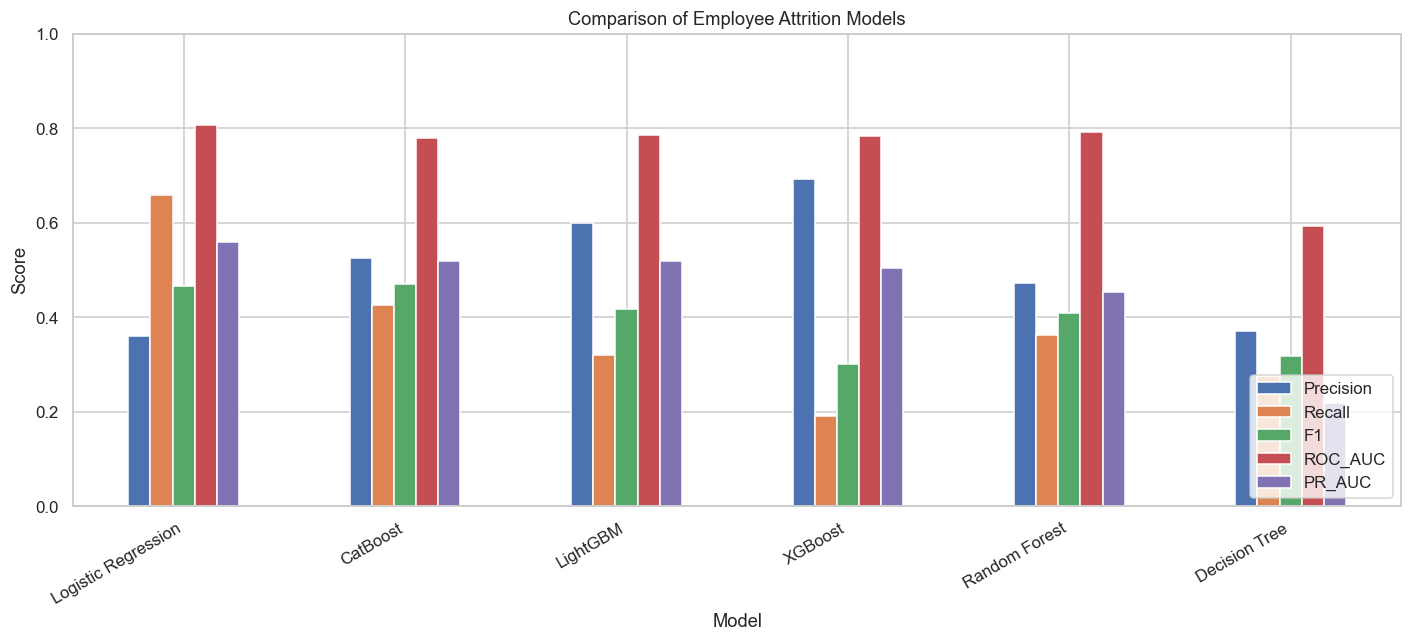

In [28]:
metrics_to_plot = [
    "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"
]

plot_df = results_df.set_index("Model")[metrics_to_plot]

ax = plot_df.plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1)
)

ax.set_title("Comparison of Employee Attrition Models")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "model_comparison.png",
    bbox_inches="tight"
)
plt.show()

C:\Users\adity\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


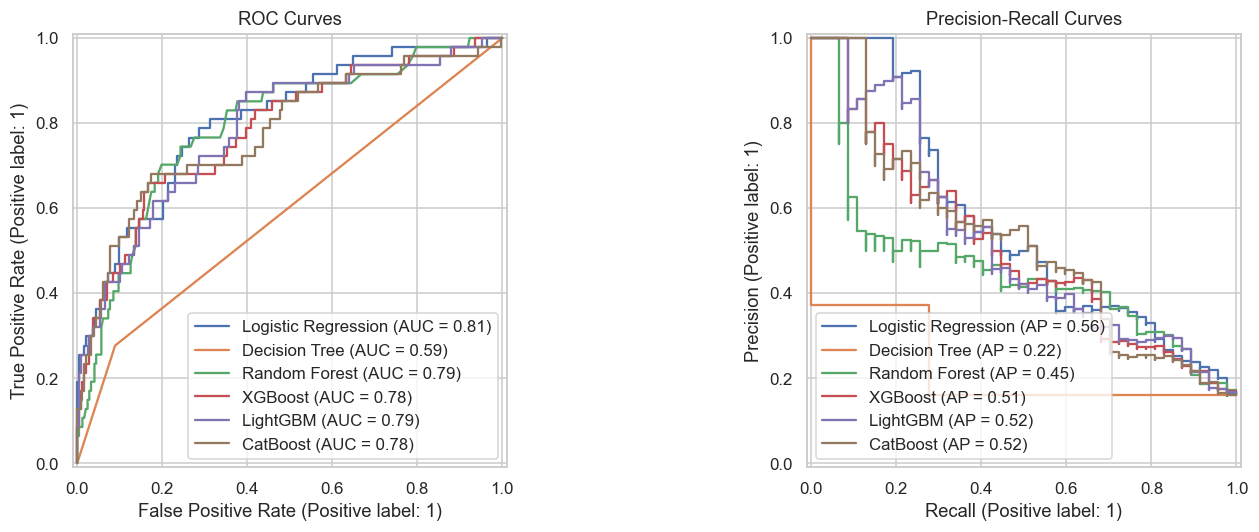

In [30]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model_name, pipeline in trained_models.items():
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=model_name,
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        y_test,
        y_prob,
        name=model_name,
        ax=axes[1]
    )

axes[0].set_title("ROC Curves")
axes[1].set_title("Precision-Recall Curves")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "roc_pr_curves.png",
    bbox_inches="tight"
)
plt.show()

In [32]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 3, 5],
    "classifier__max_features": ["sqrt", 0.8]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("Best cross-validation PR-AUC:")
print(grid_search.best_score_)

best_rf = grid_search.best_estimator_

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters:
{'classifier__max_depth': 10, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 400}
Best cross-validation PR-AUC:
0.5766477377760293


In [34]:
lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

lr_grid = GridSearchCV(
    lr_pipeline,
    {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__solver": ["lbfgs"]
    },
    scoring="average_precision",
    cv=cv,
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Best Logistic Regression parameters:", lr_grid.best_params_)
print("Best CV PR-AUC:", lr_grid.best_score_)

Best Logistic Regression parameters: {'classifier__C': 0.01, 'classifier__solver': 'lbfgs'}
Best CV PR-AUC: 0.6446911449183087


In [36]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

# Preserve original column ordering: numerical first, categorical second.
num_cols = numerical_features
cat_cols = categorical_features

numeric_stage = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_stage = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

# SMOTENC needs categorical variables represented as integer codes.
mixed_preprocessor = ColumnTransformer([
    ("num", numeric_stage, num_cols),
    ("cat", categorical_stage, cat_cols)
])

# Categorical columns occupy the positions after numeric columns.
categorical_indices = list(
    range(len(num_cols), len(num_cols) + len(cat_cols))
)

# After SMOTENC, convert categorical codes into one-hot features.
final_encoder = ColumnTransformer([
    ("num", "passthrough", list(range(len(num_cols)))),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_indices)
])

smote_pipeline = ImbPipeline([
    ("preprocessor", mixed_preprocessor),
    ("sampler", SMOTENC(
        categorical_features=categorical_indices,
        random_state=RANDOM_STATE,
        k_neighbors=5
    )),
    ("onehot", final_encoder),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

smote_pipeline.fit(X_train, y_train)

smote_prob = smote_pipeline.predict_proba(X_test)[:, 1]
smote_pred = smote_pipeline.predict(X_test)

print("SMOTENC + Logistic Regression")
print("Precision:", precision_score(y_test, smote_pred))
print("Recall:", recall_score(y_test, smote_pred))
print("F1:", f1_score(y_test, smote_pred))
print("ROC-AUC:", roc_auc_score(y_test, smote_prob))
print("PR-AUC:", average_precision_score(y_test, smote_prob))

SMOTENC + Logistic Regression
Precision: 0.4166666666666667
Recall: 0.5319148936170213
F1: 0.4672897196261682
ROC-AUC: 0.7992075114135584
PR-AUC: 0.5687954860500328


In [38]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Split the existing training data.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE
)

# Rebuild Logistic Regression pipeline.
lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid={
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__solver": ["lbfgs"]
    },
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True
)

lr_search.fit(X_fit, y_fit)

print("Best parameters:", lr_search.best_params_)
print("Best cross-validation PR-AUC:", round(lr_search.best_score_, 4))

Best parameters: {'classifier__C': 0.01, 'classifier__solver': 'lbfgs'}
Best cross-validation PR-AUC: 0.6211


In [40]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

val_prob = lr_search.best_estimator_.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.10, 0.81, 0.05):
    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, val_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(3).sort_values(
        "Threshold"
    ).reset_index(drop=True)
)

,Threshold,Accuracy,Precision,Recall,F1
0,0.10,0.182,0.162,0.974,0.277
1,0.15,0.267,0.174,0.947,0.294
2,0.20,0.356,0.190,0.921,0.315
3,0.25,0.419,0.204,0.895,0.332
4,0.30,0.462,0.217,0.895,0.349
5,0.35,0.521,0.230,0.842,0.362
6,0.40,0.636,0.286,0.842,0.427
7,0.45,0.725,0.345,0.789,0.480
8,0.50,0.763,0.378,0.737,0.500
9,0.55,0.822,0.463,0.658,0.543


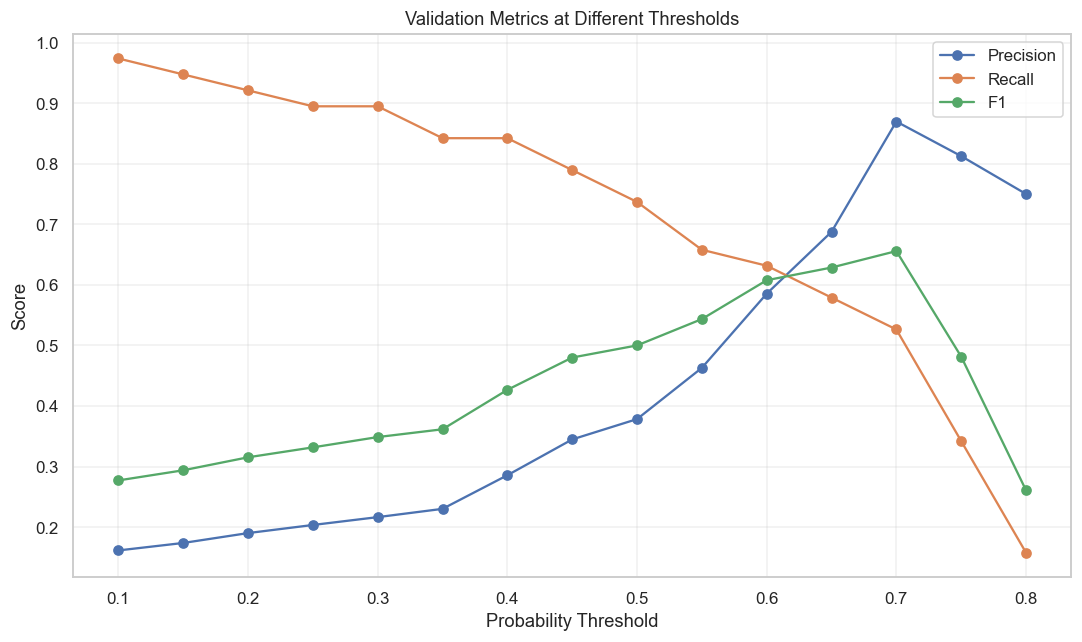

In [42]:
plt.figure(figsize=(10, 6))

for metric in ["Precision", "Recall", "F1"]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Validation Metrics at Different Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "threshold_comparison.png",
    bbox_inches="tight"
)
plt.show()